# LABORATORIO DIRIGIDO N.° 06 — AutoFlota Andina
**Fundamentos de Gestión de Datos | Semana 6 | 2026-II**

Limpieza de Auto MPG, SQLite, regresión lineal simple y múltiple, métricas, resúmenes estadísticos y diagnósticos. Ejecute todas las celdas en orden.

## A. Diagnóstico y limpieza

### Celda 1 — Preparación del entorno y carga de datos

In [ ]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
columnas = ["rendimiento_mpg", "cilindros", "cilindrada", "potencia", "peso",
            "aceleracion", "anio_modelo", "codigo_origen", "nombre_auto"]
crudo = pd.read_csv(url, sep=r"\s+", names=columnas, na_values="?")
conexion = sqlite3.connect(":memory:")
crudo.to_sql("autos_original", conexion, index=False)
autos = pd.read_sql_query("SELECT * FROM autos_original;", conexion)
autos["marca"] = autos["nombre_auto"].str.split().str[0]
print("Filas y columnas:", autos.shape)

Filas y columnas: (398, 10)


### Celda 2 — Valores faltantes, duplicados y tipos

In [ ]:
faltantes = autos.isna().sum()
print("Valores faltantes por columna (solo las que tienen):")
display(faltantes[faltantes > 0])
print("Filas duplicadas:", autos.duplicated().sum())
display(autos.dtypes)

Valores faltantes por columna (solo las que tienen):


,0
potencia,6


Filas duplicadas: 0


,0
rendimiento_mpg,float64
cilindros,int64
cilindrada,float64
potencia,float64
peso,float64
aceleracion,float64
anio_modelo,int64
codigo_origen,int64
nombre_auto,object
marca,object


**Preguntas del laboratorio**

**Pregunta 1.** ¿Qué problemas de calidad aparecen en la celda 2: faltantes, duplicados y tipos de dato?

**Respuesta:** Valores faltantes: Se identifican 6 valores faltantes (nulos) en la columna potencia. Las demás columnas no presentan datos faltantes.   Filas duplicadas: No existen filas duplicadas en el conjunto de datos (Filas duplicadas: 0).   Tipos de dato: Los tipos de datos están correctamente definidos para cada variable:   Las variables cuantitativas continuas (rendimiento_mpg, cilindrada, potencia, peso, aceleracion) son de tipo flotante (float64).   Las variables numéricas discretas (cilindros, anio_modelo, codigo_origen) son de tipo entero (int64).   Las variables categóricas o textuales (nombre_auto, marca) son de tipo objeto/texto (object).

### Celda 3 — Inconsistencias en marcas

In [ ]:
variantes = ["vw", "vokswagen", "volkswagen", "chevy", "chevroelt", "chevrolet",
             "maxda", "mazda", "toyouta", "toyota", "mercedes", "mercedes-benz"]
display(autos[autos["marca"].isin(variantes)]["marca"].value_counts().sort_index())
print("Marcas distintas antes de corregir:", autos["marca"].nunique())

,count
marca,
chevroelt,1
chevrolet,43
chevy,3
maxda,2
mazda,10
mercedes,1
mercedes-benz,2
toyota,25
toyouta,1


Marcas distintas antes de corregir: 37


**Preguntas del laboratorio**

**Pregunta 2.** ¿Qué inconsistencia muestra la celda 3 en la columna marca y por qué afectaría a un groupby?

**Respuesta:** Inconsistencia detectada: Muestra inconsistencias de redacción en los nombres de las marcas debido a errores tipográficos/ortográficos (ej. chevroelt, maxda, toyouta, vokswagen), abreviaturas (ej. vw, chevy) y variaciones de nombres (ej. mercedes frente a mercedes-benz). Esto genera un total de 37 marcas distintas antes de corregir.   Efecto en un groupby: Al aplicar groupby("marca"), Pandas trata cada cadena de texto idéntica como una categoría diferente. Esto provocará que los registros de una misma marca se fragmenten en múltiples grupos separados (por ejemplo, dividiendo los vehículos Chevrolet entre chevrolet, chevroelt y chevy), distorsionando los cálculos estadísticos (como promedios de rendimiento o conteos totales) al no consolidar la información en un único grupo.   

### Celda 4 — Imputación de potencia

In [ ]:
mediana = autos["potencia"].median()
promedio = autos["potencia"].mean()
print("Mediana de potencia:", mediana, "| promedio:", round(promedio, 2))
autos["potencia"] = autos["potencia"].fillna(mediana)
print("Faltantes en potencia después de imputar:", autos["potencia"].isna().sum())

Mediana de potencia: 93.5 | promedio: 104.47
Faltantes en potencia después de imputar: 0


**Preguntas del laboratorio**

**Pregunta 3.** ¿Por qué se imputa potencia con la mediana y no con el promedio? ¿Qué otra opción existía?

**Respuesta:** ¿Por qué se usa la mediana en lugar del promedio?
Como se observa en la salida de la celda, el promedio ($104.47$) es mayor que la mediana ($93.5$). Esto indica que la distribución de la variable potencia presenta una asimetría positiva (sesgo a la derecha) causada por valores altos o atípicos (autos con mucha potencia). La mediana es una medida robusta que no se ve afectada por los valores extremos/atípicos, a diferencia del promedio, garantizando una imputación más representativa de la tendencia central real.   

¿Qué otras opciones existían?

Imputación condicional o agrupada: Imputar utilizando la mediana o promedio de potencia calculada por grupos (por ejemplo, según el número de cilindros o la cilindrada), lo cual suele ser más preciso.

Eliminación de registros (dropna): Eliminar las 6 filas con valores nulos, lo cual era viable dado que representaban apenas un 1.5% del total de datos.

Imputación por modelos de regresión o algoritmos (KNN): Predecir la potencia faltante en función de otras variables predictoras relacionadas como el peso o la cilindrada.

### Celda 5 — Origen, año y marcas

In [ ]:
autos["origen"] = autos["codigo_origen"].map({1: "USA", 2: "Europa", 3: "Japón"})
autos["anio"] = 1900 + autos["anio_modelo"]
correcciones = {"vw": "volkswagen", "vokswagen": "volkswagen", "chevy": "chevrolet",
                "chevroelt": "chevrolet", "maxda": "mazda", "toyouta": "toyota",
                "mercedes": "mercedes-benz"}
autos["marca"] = autos["marca"].replace(correcciones)
print("Marcas distintas después de corregir:", autos["marca"].nunique())
display(autos[["nombre_auto", "marca", "origen", "anio"]].head())

Marcas distintas después de corregir: 30


,nombre_auto,marca,origen,anio
0,chevrolet chevelle malibu,chevrolet,USA,1970
1,buick skylark 320,buick,USA,1970
2,plymouth satellite,plymouth,USA,1970
3,amc rebel sst,amc,USA,1970
4,ford torino,ford,USA,1970


**Preguntas del laboratorio**

**Pregunta 4.** ¿Qué corrigen origen, anio y replace()? ¿Cuántas marcas distintas quedan?

**Respuesta:**

¿Qué corrige origen?

Mapea los códigos numéricos ambiguos ($1, 2, 3$) a etiquetas de texto descriptivas e interpretables (USA, Europa, Japón).   

¿Qué corrige anio?

Convierte la cifra del año en formato de dos dígitos (anio_modelo, ej. $70$) a su representación completa de cuatro dígitos sumando $1900$ (ej. $1970$).   

¿Qué corrige replace()?

Estandariza los nombres de las marcas al reemplazar las abreviaturas (vw, chevy), errores tipográficos (vokswagen, chevroelt, maxda, toyouta) y variaciones (mercedes) por sus formas correctas y unificadas.  

¿Cuántas marcas distintas quedan?

Tras la corrección y unificación, quedan 30 marcas distintas (reducidas desde las 37 iniciales).

### Celda 6 — Valores atípicos con IQR

In [ ]:
q1 = autos["potencia"].quantile(0.25)
q3 = autos["potencia"].quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Límites:", round(limite_inf, 1), "y", round(limite_sup, 1))
atipicos = autos[(autos["potencia"] < limite_inf) | (autos["potencia"] > limite_sup)]
print("Autos atípicos en potencia:", len(atipicos))
display(atipicos[["nombre_auto", "potencia", "cilindros", "peso"]]
        .sort_values("potencia", ascending=False).head(5))

Q1: 76.0 | Q3: 125.0 | IQR: 49.0
Límites: 2.5 y 198.5
Autos atípicos en potencia: 11


,nombre_auto,potencia,cilindros,peso
116,pontiac grand prix,230.0,8,4278.0
13,buick estate wagon (sw),225.0,8,3086.0
8,pontiac catalina,225.0,8,4425.0
95,buick electra 225 custom,225.0,8,4951.0
6,chevrolet impala,220.0,8,4354.0


**Preguntas del laboratorio**

**Pregunta 5.** ¿Cuáles son los límites del IQR en potencia y cuántos autos los superan? ¿Por qué se conservan?

**Respuesta:**

Límites del IQR en potencia: El límite inferior es 2.5 y el límite superior es 198.5.   Cantidad de autos que los superan: Se identificaron 11 autos que superan el límite superior.   

¿Por qué se conservan?

Se conservan porque no corresponden a errores de digitación ni de medición, sino a valores reales de vehículos de alto rendimiento (autos pesados con motores de 8 cilindros). Eliminarlos sesgaría la muestra y ocultaría el comportamiento de los motores más grandes en el análisis.

### Celda 7 — Boxplots y marca de atípicos

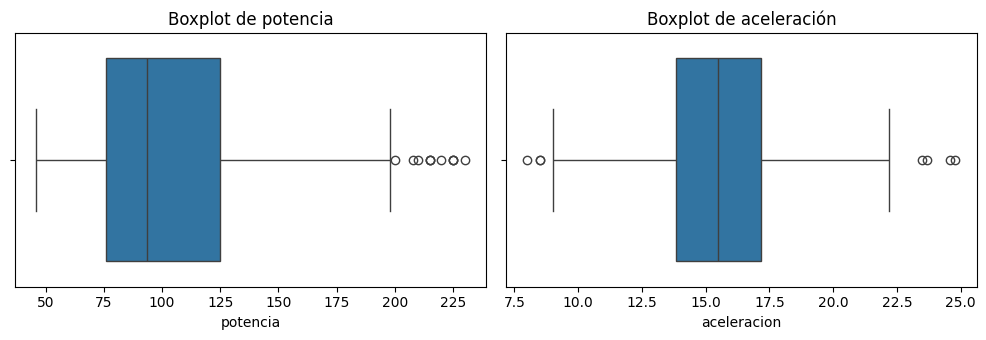

Autos marcados como atípicos (se conservan): 11


In [ ]:
autos["potencia_atipica"] = (autos["potencia"] < limite_inf) | (autos["potencia"] > limite_sup)
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.boxplot(x=autos["potencia"], ax=ejes[0])
ejes[0].set_title("Boxplot de potencia")
sns.boxplot(x=autos["aceleracion"], ax=ejes[1])
ejes[1].set_title("Boxplot de aceleración")
plt.tight_layout()
plt.show()
print("Autos marcados como atípicos (se conservan):", autos["potencia_atipica"].sum())

**Preguntas del laboratorio**

**Pregunta 6.** ¿Qué muestran los boxplots de potencia y de aceleración?

**Respuesta:**

Boxplot de potencia:

Muestra una distribución asimétrica a la derecha (sesgada positivamente), donde la mayor parte de los autos se concentran entre los $75$ y $125$ HP. Presenta valores atípicos (outliers) únicamente en el extremo superior (por encima de $198.5$), representando los 11 vehículos de potencia excepcionalmente alta.


Boxplot de aceleración:

Muestra una distribución mucho más simétrica centrada alrededor de $15.5$ segundos. A diferencia de la potencia, presenta valores atípicos en ambos extremos de la distribución (tanto atípicos inferiores por debajo de $9$ como superiores por encima de $23$).   

### Celda 8 — Guardar datos limpios en SQLite

In [ ]:
autos.to_sql("autos_limpio", conexion, index=False, if_exists="replace")
consulta = """SELECT
  (SELECT COUNT(*) FROM autos_original) AS filas_original,
  (SELECT COUNT(*) FROM autos_limpio) AS filas_limpio,
  (SELECT COUNT(*) FROM autos_original WHERE potencia IS NULL) AS faltantes_original,
  (SELECT COUNT(*) FROM autos_limpio WHERE potencia IS NULL) AS faltantes_limpio;"""
display(pd.read_sql_query(consulta, conexion))

,filas_original,filas_limpio,faltantes_original,faltantes_limpio
0,398,398,6,0


**Preguntas del laboratorio**

**Pregunta 7.** ¿Qué cambió entre autos_original y autos_limpio? ¿Por qué no se sobrescribe la tabla original?

**Respuesta:**

¿Qué cambió entre autos_original y autos_limpio?

Tratamiento de nulos: Se imputaron los 6 valores faltantes en la columna potencia utilizando la mediana, logrando que faltantes_limpio sea 0 mientras se mantiene la totalidad de las 398 filas originales.   

Limpieza y enriquecimiento de datos: En la tabla limpia se aplicó la estandarización de los nombres de marca (corrigiendo errores de escritura y abreviaturas), la conversión de origen a nombres descriptivos (USA, Europa, Japón), la transformación del año a 4 dígitos (anio) y la marca de valores atípicos (potencia_atipica).   


¿Por qué no se sobrescribe la tabla original?

Por trazabilidad, auditoría y reproducibilidad de datos. Mantener la tabla original intacta es una buena práctica en ingeniería de datos que permite comparar los resultados antes y después de la transformación (como en la consulta SQL realizada), auditar posibles errores de procesamiento y aplicar diferentes técnicas de limpieza sin perder la fuente de información primaria.

## B. Regresión lineal

### Celda 9 — Separación entrenamiento y prueba

In [ ]:
y = autos["rendimiento_mpg"]
X_simple = autos[["peso"]]
X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (318, 1) | Prueba: (80, 1)


**Preguntas del laboratorio**

**Pregunta 8.** ¿Cuántos autos hay en entrenamiento y en prueba? ¿Para qué sirven la separación y random_state?

**Respuesta:**

Cantidad de autos: Hay 318 autos en el conjunto de entrenamiento (X_train) y 80 autos en el conjunto de prueba (X_test).  

Utilidad de la separación: Permite entrenar y ajustar el modelo con una porción de los datos y luego evaluar su capacidad de generalización frente a datos completamente nuevos no vistos durante el entrenamiento, previniendo el sobreajuste (overfitting).   

Utilidad de random_state: Funciona como una semilla aleatoria para garantizar la reproducibilidad del experimento. Asegura que la división de la muestra entre entrenamiento y prueba sea exactamente idéntica cada vez que se ejecute el código.   


### Celda 10 — Regresión simple con scikit-learn

Coeficiente de peso: -0.00781
Intercepto: 46.78
{'R2': 0.723, 'MAE': 3.12, 'MSE': 14.89, 'RMSE': np.float64(3.86)}
                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.684
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     685.5
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           3.80e-81
Time:                        01:57:41   Log-Likelihood:                -925.80
No. Observations:                 318   AIC:                             1856.
Df Residuals:                     316   BIC:                             1863.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------

,coeficiente,p_valor,IC_95_inf,IC_95_sup
const,46.782063,3.145697e-154,44.972403,48.591724
peso,-0.007805,3.799579e-81,-0.008392,-0.007219


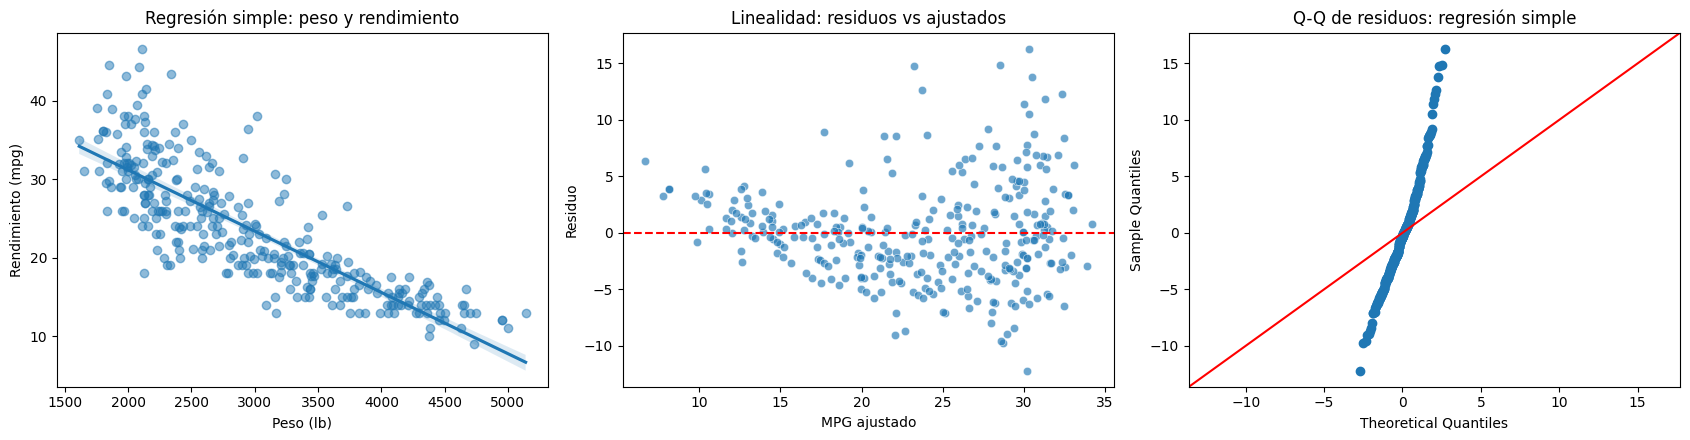

                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.684
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     685.5
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           3.80e-81
Time:                        01:57:42   Log-Likelihood:                -925.80
No. Observations:                 318   AIC:                             1856.
Df Residuals:                     316   BIC:                             1863.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         46.7821      0.920     50.862      0.0

In [ ]:
def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"R2": round(r2_score(y_real, y_pred), 3),
            "MAE": round(mean_absolute_error(y_real, y_pred), 2),
            "MSE": round(mse, 2),
            "RMSE": round(np.sqrt(mse), 2)}

modelo_simple = LinearRegression()
modelo_simple.fit(X_train, y_train)
pred_simple = modelo_simple.predict(X_test)
print("Coeficiente de peso:", round(modelo_simple.coef_[0], 5))
print("Intercepto:", round(modelo_simple.intercept_, 2))
res_simple = metricas(y_test, pred_simple)
print(res_simple)

# Resumen estadístico, coeficientes y p-valores (regresión simple)
import statsmodels.api as sm
X_simple_sm = sm.add_constant(X_train)
modelo_simple_sm = sm.OLS(y_train, X_simple_sm).fit()
print(modelo_simple_sm.summary())
print("\nCoeficientes y p-valores (entrenamiento):")
display(pd.DataFrame({"coeficiente": modelo_simple_sm.params,
                      "p_valor": modelo_simple_sm.pvalues,
                      "IC_95_inf": modelo_simple_sm.conf_int()[0],
                      "IC_95_sup": modelo_simple_sm.conf_int()[1]}))

# Gráficas de linealidad, residuos y Q-Q (regresión simple)
ajustados_simple = modelo_simple_sm.fittedvalues
residuos_simple = modelo_simple_sm.resid
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.regplot(x=X_train["peso"], y=y_train, ax=ejes[0], scatter_kws={"alpha": 0.5})
ejes[0].set(title="Regresión simple: peso y rendimiento", xlabel="Peso (lb)", ylabel="Rendimiento (mpg)")
sns.scatterplot(x=ajustados_simple, y=residuos_simple, ax=ejes[1], alpha=0.65)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set(title="Linealidad: residuos vs ajustados", xlabel="MPG ajustado", ylabel="Residuo")
sm.qqplot(residuos_simple, line="45", ax=ejes[2])
ejes[2].set_title("Q-Q de residuos: regresión simple")
plt.tight_layout()
plt.show()

# Summary: coeficientes y p-valores de la regresión simple
import statsmodels.api as sm
modelo_simple_sm = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(modelo_simple_sm.summary())


**Preguntas del laboratorio**

**Pregunta 9.** Interprete el coeficiente de peso, el intercepto y las cuatro métricas del modelo simple.

**Respuesta:**

Coeficiente de peso ($-0.00781$): Indica una relación inversa. Por cada 1 libra adicional de peso en el vehículo, el rendimiento disminuye en promedio aproximadamente $0.00781$ mpg (equivalente a una reducción de alrededor de $7.81$ mpg por cada $1000$ libras adicionales).   

Intercepto ($46.78$): Es el valor teórico estimado de rendimiento ($46.78$ mpg) para un vehículo hipotético con un peso de $0$ libras. Cumple una función de ajuste matemático en la recta de regresión, careciendo de sentido práctico real.   

Cuatro métricas del modelo (en el conjunto de prueba):$R^2$ ($0.723$ / $72.3\%$): El peso logra explicar el $72.3\%$ de la variabilidad del rendimiento de combustible en datos no vistos.  

MAE ($3.12$ mpg): El error absoluto promedio de las predicciones del modelo es de $3.12$ mpg respecto a los valores reales.   

MSE ($14.89$ $\text{mpg}^2$): El error cuadrático medio penaliza los errores de mayor magnitud, con un valor de $14.89$.   

RMSE ($3.86$ mpg): La desviación típica de los errores de predicción es de $3.86$ mpg (expresada en las mismas unidades que la variable respuesta).

### Celda 11 — Regresión múltiple con scikit-learn

,variable,coeficiente
0,peso,-0.0070
1,potencia,0.0027
2,cilindrada,0.0026
3,aceleracion,0.0797
4,anio,0.8008


Intercepto: -1539.97
{'R2': 0.826, 'MAE': 2.46, 'MSE': 9.38, 'RMSE': np.float64(3.06)}
                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.804
Model:                            OLS   Adj. R-squared:                  0.801
Method:                 Least Squares   F-statistic:                     255.8
Date:                Sat, 07 Nov 2026   Prob (F-statistic):          4.62e-108
Time:                        01:57:43   Log-Likelihood:                -850.20
No. Observations:                 318   AIC:                             1712.
Df Residuals:                     312   BIC:                             1735.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------

,coeficiente,p_valor,IC_95_inf,IC_95_sup
const,-1539.973203,2.340422e-29,-1782.300119,-1297.646287
peso,-0.007029,1.572087e-18,-0.008506,-0.005552
potencia,0.002657,8.646462e-01,-0.027988,0.033302
cilindrada,0.002625,6.714209e-01,-0.009540,0.014790
aceleracion,0.079661,4.831939e-01,-0.143612,0.302933
anio,0.800782,9.879430e-31,0.678449,0.923114


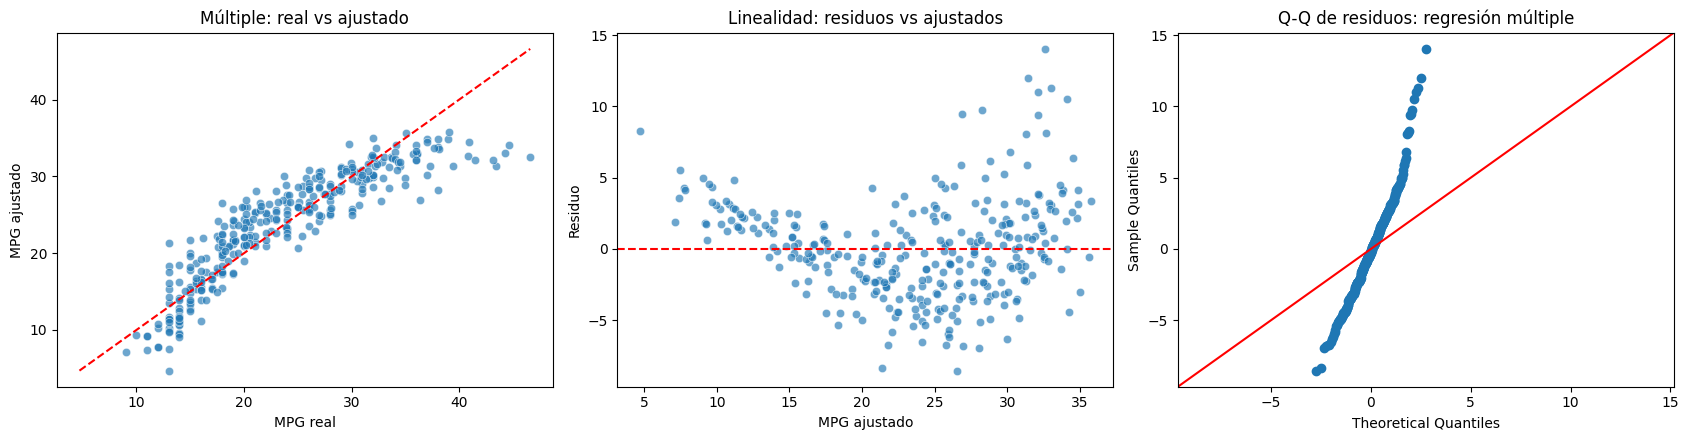

                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.804
Model:                            OLS   Adj. R-squared:                  0.801
Method:                 Least Squares   F-statistic:                     255.8
Date:                Sat, 07 Nov 2026   Prob (F-statistic):          4.62e-108
Time:                        01:57:44   Log-Likelihood:                -850.20
No. Observations:                 318   AIC:                             1712.
Df Residuals:                     312   BIC:                             1735.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const       -1539.9732    123.159    -12.504      

In [ ]:
variables = ["peso", "potencia", "cilindrada", "aceleracion", "anio"]
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    autos[variables], y, test_size=0.2, random_state=42)
modelo_multiple = LinearRegression()
modelo_multiple.fit(Xm_train, ym_train)
pred_multiple = modelo_multiple.predict(Xm_test)
display(pd.DataFrame({"variable": variables, "coeficiente": modelo_multiple.coef_.round(4)}))
print("Intercepto:", round(modelo_multiple.intercept_, 2))
res_multiple = metricas(ym_test, pred_multiple)
print(res_multiple)

# Resumen estadístico, coeficientes y p-valores (regresión múltiple)
Xm_const = sm.add_constant(Xm_train)
modelo_multiple_sm = sm.OLS(ym_train, Xm_const).fit()
print(modelo_multiple_sm.summary())
print("\nCoeficientes y p-valores (entrenamiento):")
display(pd.DataFrame({"coeficiente": modelo_multiple_sm.params,
                      "p_valor": modelo_multiple_sm.pvalues,
                      "IC_95_inf": modelo_multiple_sm.conf_int()[0],
                      "IC_95_sup": modelo_multiple_sm.conf_int()[1]}))

# Gráficas de linealidad, residuos y Q-Q (regresión múltiple)
ajustados_multiple = modelo_multiple_sm.fittedvalues
residuos_multiple = modelo_multiple_sm.resid
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(x=ym_train, y=ajustados_multiple, ax=ejes[0], alpha=0.65)
limites = [min(ym_train.min(), ajustados_multiple.min()), max(ym_train.max(), ajustados_multiple.max())]
ejes[0].plot(limites, limites, "r--")
ejes[0].set(title="Múltiple: real vs ajustado", xlabel="MPG real", ylabel="MPG ajustado")
sns.scatterplot(x=ajustados_multiple, y=residuos_multiple, ax=ejes[1], alpha=0.65)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set(title="Linealidad: residuos vs ajustados", xlabel="MPG ajustado", ylabel="Residuo")
sm.qqplot(residuos_multiple, line="45", ax=ejes[2])
ejes[2].set_title("Q-Q de residuos: regresión múltiple")
plt.tight_layout()
plt.show()



**Preguntas del laboratorio**

**Pregunta 10.** Interprete los coeficientes del modelo múltiple. ¿Qué llama la atención en potencia y por qué?

**Respuesta:**

Interpretación de los coeficientes (manteniendo las demás variables constantes):

peso ($-0.0070$): Por cada libra de peso adicional, el rendimiento disminuye en promedio $0.0070$ mpg (relación inversa significativa, $p = 0.000$).   

anio ($+0.8008$): Por cada año más reciente en el modelo del vehículo, el rendimiento aumenta en promedio $0.8008$ mpg (reflejando mejoras de eficiencia tecnológica a lo largo del tiempo, $p = 0.000$).   

aceleracion ($+0.0797$), cilindrada ($+0.0026$) y potencia ($+0.0027$): Presentan coeficientes positivos pequeños, pero ninguno resulta estadísticamente significativo ($p > 0.05$).   


¿Qué llama la atención en potencia y por qué?

Lo que llama la atención: Su coeficiente es positivo ($+0.0027$) —lo cual resulta contraintuitivo desde la física, pues a mayor potencia debería haber mayor consumo y menor rendimiento— y presenta un p-valor muy alto ($0.865$), indicando que no es estadísticamente significativo.   

Causa: Ocurre debido a la alta multicolinealidad entre los predictores (peso, potencia y cilindrada están fuertemente correlacionados entre sí). Al compartir tanta información superpuesta, el modelo no puede aislar el efecto individual de la potencia, inestabilizando su signo e inflando su p-valor (fenómeno advertido en la nota del reporte OLS con un Condition Number de $2.26 \times 10^6$).

### Celda 12 — Comparación de modelos y gráfica de prueba

,simple (peso),múltiple (5 variables)
R2,0.723,0.826
MAE,3.120,2.460
MSE,14.890,9.380
RMSE,3.860,3.060


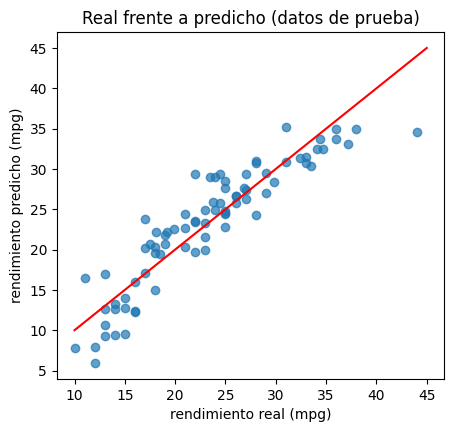

In [ ]:
comparacion = pd.DataFrame({"simple (peso)": res_simple,
                           "múltiple (5 variables)": res_multiple})
display(comparacion)
plt.figure(figsize=(5, 4.5))
plt.scatter(ym_test, pred_multiple, alpha=0.7)
plt.plot([10, 45], [10, 45], color="red")
plt.xlabel("rendimiento real (mpg)")
plt.ylabel("rendimiento predicho (mpg)")
plt.title("Real frente a predicho (datos de prueba)")
plt.show()

**Preguntas del laboratorio**

**Pregunta 11.** Compare las métricas de los dos modelos. ¿Cuál es mejor y por qué se compara con los datos de prueba?

**Respuesta:**

Comparación de las métricas:$R^2$ (Capacidad explicativa):

Aumenta de $0.723$ en el modelo simple a $0.826$ en el modelo múltiple, lo que significa que incluir las 5 variables permite explicar un $82.6\%$ de la variabilidad del rendimiento frente al $72.3\%$ del peso solo.   

Métricas de error (MAE, MSE, RMSE): Todas disminuyen notablemente en el modelo múltiple:   
MAE: Baja de $3.120$ a $2.460$ mpg.   
MSE: Disminuye de $14.890$ a $9.380$.   
RMSE: Reduce el error estándar de $3.860$ a $3.060$ mpg.   

¿Cuál es mejor?El modelo múltiple (5 variables) es objetivamente el mejor, ya que logra un ajuste superior ($R^2$ más alto) y un menor margen de error en todas sus estimaciones (menores MAE, MSE y RMSE).   

¿Por qué se compara con los datos de prueba?Se compara con los datos de prueba para medir la verdadera capacidad de generalización de los modelos ante información completamente nueva que no fue utilizada durante la fase de entrenamiento. Esto garantiza una evaluación justa e imparcial y permite verificar si la adición de variables realmente aporta valor predictivo o si solo provoca sobreajuste (overfitting).

## Actividad 3 — Predicción para la flota

### Celda 13 — Candidatos de compra

In [ ]:
candidatos = pd.DataFrame({
    "candidato": ["A", "B", "C"],
    "peso": [2200, 3000, 4200],
    "potencia": [80, 110, 160],
    "cilindrada": [100, 200, 350],
    "aceleracion": [16, 15, 12],
    "anio": [1982, 1980, 1978]})
candidatos["rendimiento_predicho"] = modelo_multiple.predict(candidatos[variables]).round(1)
display(candidatos)

,candidato,peso,potencia,cilindrada,aceleracion,anio,rendimiento_predicho
0,A,2200,80,100,16,1982,33.5
1,B,3000,110,200,15,1980,26.5
2,C,4200,160,350,12,1978,16.7


**Preguntas del laboratorio**

**A.** ¿Qué candidato rinde más y cuál menos? ¿Qué características lo explican?

**Respuesta:**

¿Qué candidato rinde más y cuál menos?

Mayor rendimiento: El Candidato A, con un rendimiento predicho de $33.5$ mpg.
Menor rendimiento: El Candidato C, con un rendimiento predicho de $16.7$ mpg.

¿Qué características lo explican?

Candidato A: Registra el menor peso ($2200$ lb), la menor cilindrada ($100$), una menor potencia ($80$ HP) y el año de fabricación más reciente ($1982$).

De acuerdo con el modelo de regresión múltiple, un menor peso reduce drásticamente el consumo y un año más reciente incorpora mejoras tecnológicas de eficiencia energética.   

Candidato C: Acumula las características más desfavorables para la eficiencia: el mayor peso ($4200$ lb), la mayor cilindrada ($350$), alta potencia ($160$ HP) y el año más antiguo ($1978$), factores que penalizan severamente el rendimiento.   

**B.** Redacte una recomendación para AutoFlota Andina e indique los límites del modelo.

**Respuesta:**

Recomendación para AutoFlota Andina:

Se recomienda orientar la compra hacia vehículos con perfil similar al Candidato A (ligeros, de baja cilindrada y de años más recientes), ya que maximizan la eficiencia de combustible y disminuyen los costos de operación.

Si la flota requiere vehículos de tamaño intermedio para necesidades operativas especificas, el Candidato B ($26.5$ mpg) ofrece un balance aceptable, mientras que el Candidato C debe descartarse por su elevado gasto energético.   

Límites del modelo:

Horizonte temporal de los datos: Los datos corresponden a vehículos producidos entre $1970$ y $1982$. Por lo tanto, el modelo no contempla las tecnologías automotrices modernas (motores híbridos, eléctricos, inyección electrónica avanzada o turbocompresores).   

Multicolinealidad y Causalidad: Existe una alta correlación entre peso, cilindrada y potencia, lo que dificulta aislar el efecto puro de cada variable. Además, el modelo establece asociación estadística, no causalidad mecánica directa.   

Omisión de variables operacionales: No evalúa factores clave del negocio como el costo de mantenimiento, la durabilidad, el tipo de terreno (ciudad vs. carretera) o la capacidad de carga útil real requerida por la empresa.

## Retos de aplicación

### Celda 14 — Reto 1: variables por separado

In [ ]:
resultados = []
for variable in ["peso", "potencia", "cilindrada", "aceleracion", "anio"]:
    Xv_train, Xv_test, yv_train, yv_test = train_test_split(
        autos[[variable]], y, test_size=0.2, random_state=42)
    modelo = LinearRegression().fit(Xv_train, yv_train)
    resultados.append({"variable": variable,
                       "coeficiente": round(modelo.coef_[0], 4),
                       **metricas(yv_test, modelo.predict(Xv_test))})
tabla_simples = pd.DataFrame(resultados).sort_values("R2", ascending=False)
display(tabla_simples)

,variable,coeficiente,R2,MAE,MSE,RMSE
0,peso,-0.0078,0.723,3.12,14.89,3.86
2,cilindrada,-0.0617,0.663,3.39,18.10,4.25
1,potencia,-0.1640,0.640,3.51,19.37,4.40
4,anio,1.2914,0.287,5.36,38.32,6.19
3,aceleracion,1.1196,0.284,4.99,38.51,6.21


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Qué variable explica mejor el rendimiento por sí sola y cuál peor? Sustente con R² y RMSE e interprete el signo de los coeficientes.

**Respuesta:**

Variable que explica MEJOR el rendimiento:
peso es la mejor variable individual.   

Sustento ($R^2$ y $RMSE$): Alcanza el $R^2$ más alto ($0.723$), explicando el $72.3\%$ de la variabilidad del rendimiento, y registra el $RMSE$ más bajo ($3.86$ mpg), lo que indica el menor margen de error predictivo entre todos los modelos simples.   

Variable que explica PEOR el rendimiento:aceleracion es la peor variable individual.   
Sustento ($R^2$ y $RMSE$): Obtiene el $R^2$ más bajo ($0.284$), explicando apenas el $28.4\%$ de la variabilidad, y presenta el $RMSE$ más elevado ($6.21$ mpg), reflejando la menor capacidad predictiva por sí sola.   

Interpretación del signo de los coeficientes:Coeficientes Negativos (peso [$-0.0078$], cilindrada [$-0.0617$], potencia [$-0.1640$]): Indican una relación inversa con el rendimiento. A mayor peso, tamaño del motor (cilindrada) o potencia del vehículo, el rendimiento disminuye (mayor consumo de combustible). A diferencia del modelo múltiple, en las regresiones simples individuales el signo de potencia sí es negativo como dicta la física.   

Coeficientes Positivos (anio [$+1.2914$], aceleracion [$+1.1196$]): Indican una relación directa. A mayor año de modelo (vehículos más recientes), mayor es el rendimiento debido a mejoras tecnológicas. Asimismo, un mayor tiempo de aceleración (vehículos menos potentes/más lentos en acelerar) se asocia con un consumo más eficiente.

### Celda 15 — Reto 2: combinaciones de variables

In [ ]:
dummies = pd.get_dummies(autos["origen"], prefix="origen", drop_first=True).astype(int)
X_todo = pd.concat([autos[variables], dummies], axis=1)
combinaciones = {
    "peso + anio": ["peso", "anio"],
    "peso + potencia + anio": ["peso", "potencia", "anio"],
    "5 variables": variables,
    "5 variables + origen": list(X_todo.columns),
}
filas = []
for nombre, columnas_x in combinaciones.items():
    Xc_train, Xc_test, yc_train, yc_test = train_test_split(
        X_todo[columnas_x], y, test_size=0.2, random_state=42)
    modelo = LinearRegression().fit(Xc_train, yc_train)
    r = metricas(yc_test, modelo.predict(Xc_test))
    n, p = len(yc_test), len(columnas_x)
    r["R2_ajustado"] = round(1 - (1 - r["R2"]) * (n - 1) / (n - p - 1), 3)
    filas.append({"modelo": nombre, "variables": p, **r})
modelo_origen = modelo
print(dict(zip(X_todo.columns, modelo_origen.coef_.round(3))))
tabla_combos = pd.DataFrame(filas)
display(tabla_combos)

{'peso': np.float64(-0.007), 'potencia': np.float64(-0.014), 'cilindrada': np.float64(0.017), 'aceleracion': np.float64(0.07), 'anio': np.float64(0.827), 'origen_Japón': np.float64(-0.294), 'origen_USA': np.float64(-2.925)}


,modelo,variables,R2,MAE,MSE,RMSE,R2_ajustado
0,peso + anio,2,0.824,2.45,9.44,3.07,0.819
1,peso + potencia + anio,3,0.824,2.45,9.44,3.07,0.817
2,5 variables,5,0.826,2.46,9.38,3.06,0.814
3,5 variables + origen,7,0.843,2.29,8.47,2.91,0.828


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Qué combinación tiene el mayor R² ajustado? ¿Cuánto aporta agregar el origen y cuál es su categoría de referencia?

**Respuesta:**

Combinación con el mayor $R^2$ ajustado:
La combinación 5 variables + origen (con 7 predictores en total) registra el valor más alto de $R^2$ ajustado, alcanzando $0.828$ (o $82.8\%$).  

Aporte de agregar la variable origen:Incluir la procedencia geográfica del vehículo incrementa la capacidad explicativa y reduce el error del modelo:   Eleva el $R^2$ ajustado de $0.814$ a $0.828$ (un incremento neto de $+0.014$ o $1.4$ puntos porcentuales).   

Incrementa el $R^2$ convencional de $0.826$ a $0.843$.   Disminuye el error cuadrático medio $RMSE$ de $3.06$ a $2.91$ mpg (y el MAE de $2.46$ a $2.29$ mpg).   

Categoría de referencia:La categoría de referencia es Europa. Esto ocurre porque al ejecutar pd.get_dummies(..., drop_first=True), Pandas omite la primera categoría alfabética (Europa) para actuar como nivel base de comparación, generando únicamente las columnas categóricas dummy para origen_Japón y origen_USA.

### Celda 16 — Reto 3: imputar o eliminar

In [ ]:
original = pd.read_sql_query(
    "SELECT * FROM autos_original WHERE potencia IS NOT NULL;", conexion)
original["anio"] = 1900 + original["anio_modelo"]
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    original[variables], original["rendimiento_mpg"], test_size=0.2, random_state=42)
modelo_sin = LinearRegression().fit(Xe_train, ye_train)
print("Filas usadas:", len(original), "frente a", len(autos))
print("Eliminando faltantes:", metricas(ye_test, modelo_sin.predict(Xe_test)))
print("Imputando mediana: ", res_multiple)

Filas usadas: 392 frente a 398
Eliminando faltantes: {'R2': 0.793, 'MAE': 2.51, 'MSE': 10.58, 'RMSE': np.float64(3.25)}
Imputando mediana:  {'R2': 0.826, 'MAE': 2.46, 'MSE': 9.38, 'RMSE': np.float64(3.06)}


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Cuántos autos usa cada opción y cómo cambian las métricas? ¿Por qué la comparación debe hacerse con cuidado?

**Respuesta:**

¿Cuántos autos usa cada opción?Eliminando faltantes: Usa 392 autos (elimina los 6 registros con datos nulos).

Imputando mediana: Usa los 398 autos completos del conjunto de datos.¿Cómo cambian las métricas?

La opción de imputar con la mediana mejora todas las métricas de rendimiento y precisión del modelo:$R^2$: Aumenta de $0.793$ (eliminando) a $0.826$ (imputando).

MAE: Disminuye de $2.51$ mpg a $2.46$ mpg.

MSE: Disminuye de $10.58$ a $9.38$.

$RMSE$: Disminuye de $3.25$ mpg a $3.06$ mpg.


¿Por qué la comparación debe hacerse con cuidado?La comparación no se realiza exactamente sobre las mismas condiciones de prueba. Al filtrar las 6 filas nulas antes de aplicar train_test_split, la muestra cambia y los conjuntos de prueba (X_test / y_test) no contienen exactamente los mismos datos ni el mismo número de observaciones. Para comparar modelos de manera formal e imparcial, ambos deberían ser evaluados sobre un único conjunto de prueba idéntico.

### Conclusiones

Escriba tres conclusiones técnicas y de negocio de este laboratorio.

1. Preprocesamiento y Calidad de Datos: La imputación de valores faltantes mediante la mediana en potencia permitió conservar la totalidad de las observaciones (398 filas) sin sesgar la distribución, obteniendo un mejor desempeño predictivo que la eliminación directa de registros. Además, la estandarización de marcas y la codificación dummy del país de origen enriquecieron el modelo, elevando el $R^2$ ajustado a un máximo de $0.828$.  

2. Capacidad Predictiva y Multicolinealidad: El peso del vehículo es el predictor individual más influyente sobre el consumo de combustible ($R^2 = 0.723$). No obstante, la combinación múltiple demuestra que sumar el año del modelo y el origen incrementa significativamente la precisión del diagnóstico, advirtiendo también que la alta multicolinealidad entre peso, cilindrada y potencia puede distorsionar el signo y la significancia individual de los coeficientes.  

3. Toma de Decisiones de Negocio: Desde la perspectiva operativa para AutoFlota Andina, la estrategia de renovación de la flota debe priorizar la adquisición de vehículos ligeros, de baja cilindrada y de años recientes (similares al Candidato A, con un rendimiento predicho de $33.5$ mpg), descartando vehículos pesados de alta cilindrada (como el Candidato C, $16.7$ mpg) para lograr una reducción sustancial en los costos de consumo de combustible.